# Exercise 14 – Steepest descent with a line search

**Week 3 · Monte Carlo and optimisation of clusters**

A deterministic alternative to the Monte Carlo quench: compute the forces
$\mathbf F = -\nabla E$, and move along $\mathbf F$ to the point where the energy
along that line is lowest. Repeat until the forces are small. Each step is a
1D minimisation (here with `scipy.optimize.minimize_scalar`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.atoms import Cluster, LennardJones, energy_landscape, line_search_relax

calc = LennardJones()


def relax_and_show(start, atom=2):
    cluster = Cluster(calc, start, static=[True, True, False])
    initial = cluster.copy()
    path = np.array(line_search_relax(cluster, max_steps=1000))
    print(f"{len(path) - 1} line-search steps, final energy {cluster.energy:.4f}, "
          f"final position {cluster.positions[atom].round(4)}")

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    xs, ys = np.linspace(-2, 2, 160), np.linspace(-1.5, 3, 160)
    Z = energy_landscape(cluster, atom, xs, ys)
    levels = np.arange(-16, 0.001, 0.25)
    filled = axes[0].contourf(xs, ys, Z, levels=levels, cmap="autumn", alpha=0.6)
    axes[0].contour(xs, ys, Z, levels=levels, cmap="autumn", linewidths=0.5)
    fig.colorbar(filled, ax=axes[0], label="energy")
    axes[0].plot(path[:, atom, 0], path[:, atom, 1], "o-", color="C0")
    axes[0].set(aspect="equal", title="Path on the energy landscape")
    for ax, c, title in [(axes[1], initial, "start"), (axes[2], cluster, "relaxed")]:
        c.draw(ax, size=600)
        ax.set(xlim=(-2, 2), ylim=(-1.5, 2.5))
        ax.set_title(f"{title}: {ax.get_title()}")
        ax.grid(True, alpha=0.4)
    fig.tight_layout()
    plt.show()

## Atom above two fixed atoms
The steepest-descent path drops into the curved valley around the left
atom and then creeps along it in hundreds of tiny steps: each step only goes
to the bottom of the valley along the current force, which then points
almost straight back across the valley. Slow progress in narrow, curved
valleys is the classic weakness of steepest descent.

273 line-search steps, final energy -10.1544, final position [-0.      0.0511]


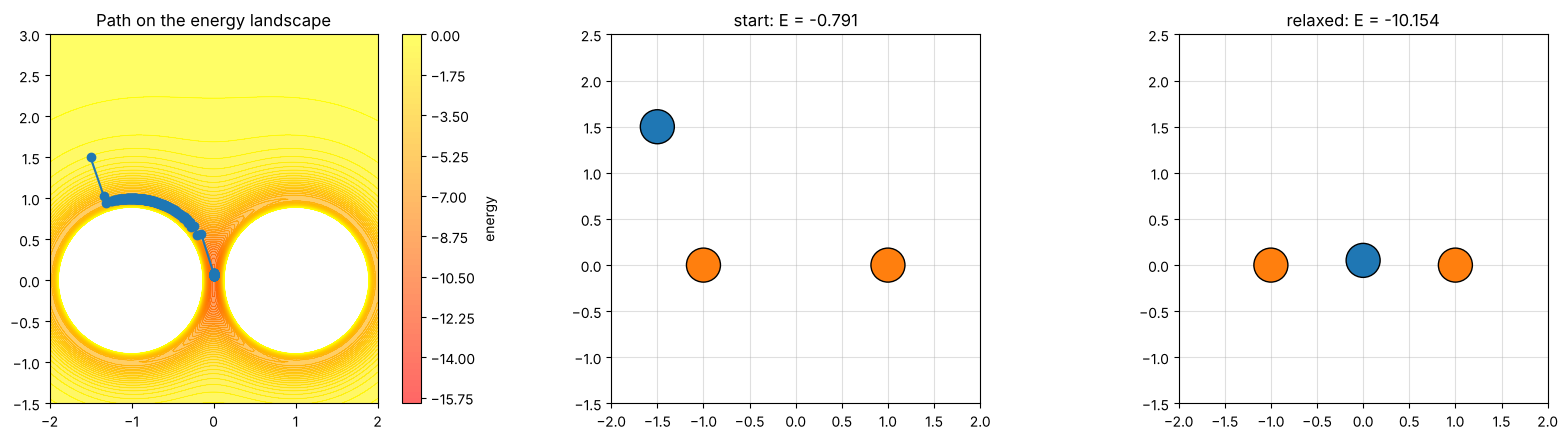

In [2]:
relax_and_show([[-1, 0], [1, 0], [-1.5, 1.5]])

## Fixed atoms closer together
Now the fixed atoms are only 1 apart, and the mobile atom settles on top of
them in an equilateral triangle.

27 line-search steps, final energy -15.0000, final position [-1.000e-04 -1.339e-01]


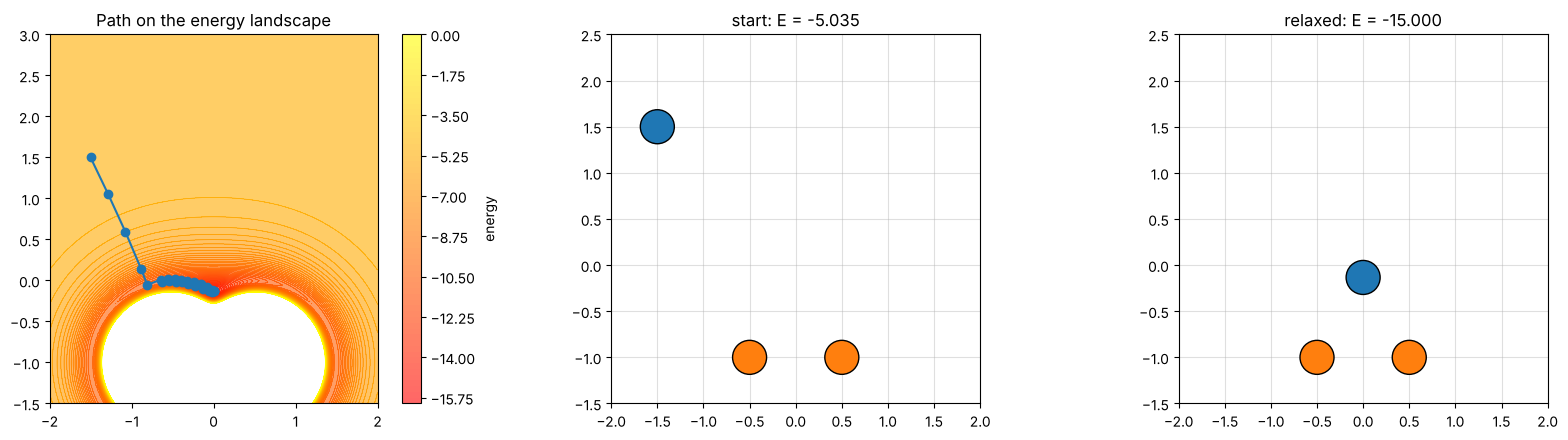

In [3]:
relax_and_show([[-0.5, -1], [0.5, -1], [-1.5, 1.5]])